# **Lab session 1**
## **Exercise 3 : Recognition of hand-written characters from the scikit-learn database using a CNN**

Start from the code you developed in exercise 2. Modify it to replace the perceptron by a two-stage CNN. The first stage will contain a unique filter layer and a maxpooling. The second stage will contain a flatten layer and one predicting dense layer.

In [44]:
"""Import necessary libraries"""
import matplotlib.pyplot as plt
import numpy as np

In [45]:
# Load the digits dataset from scikit-learn
# Import datasets and performance metrics
from sklearn import datasets
digits = datasets.load_digits()

The data we are interested in are 
8x8 images of digits. A CNN can process images directly without having them to be vectorized. Work directly with the **digits.images** from sklearn.datasets .


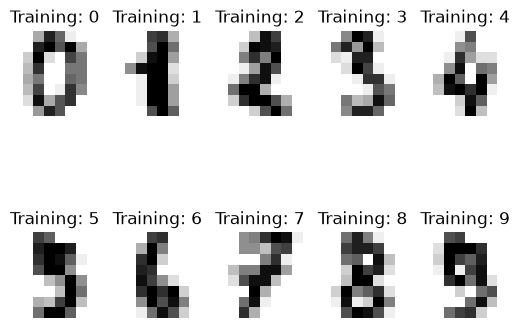

In [46]:
# The data we are interested in is made of 8x8 images of digits, let's
# have a look at the first 10 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.

images_and_labels = list(zip(digits.images, digits.target))
for index, (image, label) in enumerate(images_and_labels[:10]):
    plt.subplot(2, 5, index + 1)
    plt.axis('off')
    plt.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title('Training: %i' % label)

What is the size of the images? How many images do we have?

In [47]:
print (digits.images.shape)
print (digits.target[1:10])

(1797, 8, 8)
[1 2 3 4 5 6 7 8 9]


Again, convert the target into the matrix 'y' in one-hot format. This will allow the predictors output one at a time using the soft-max activation. What is the shape of the 'y' matrix. Use the keras function utils.to_categorical().

In [48]:
from tensorflow import keras
from tensorflow.keras import utils


n_classes = len(digits.target_names)
y= utils.to_categorical(digits.target, num_classes=n_classes)
print(f"The shape of the one-hot encoded labels is {y.shape}.")

print ("The shape of the one-hot encoded labels is", y.shape)

The shape of the one-hot encoded labels is (1797, 10).
The shape of the one-hot encoded labels is (1797, 10)


When working with images, keras CNN implicitly assume colour images.

The colours come in separate channels. These channels appear as the last dimension of the array.

Our hand-written characters are grey-tone images, that is one-channel images. We need to add
this dimension to the array to make keras understand that we only have one channel.

Print the shape of your array X. You should have a 4-D array with the last dimension equal to 1.

In [49]:
X = np.expand_dims(digits.images,axis=-1)
print (X.shape)

(1797, 8, 8, 1)


## Prepare the train and test dataset.

1.   split dataset into test and train dataset.
2.   split further the train dataset into train and validation part
Use the **keras.model_selection** function **train_test_split()** to separate a dataset. You can choose the percentage of the split, or leave the defaut value.

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=digits.target)
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=np.argmax(y_train, axis=1)
)

## create a sequential model

1.   The model will the keras sequential model containing a usual two-stage CNN.
Instantiate the model using **model=Sequential()**. 
Add a first convolution layer **Conv2D()**. Specify the number of filters (start with 5), the filter size (say 3x3), the input shape, and the type of activation - choose 'relu'.
Add a **MaxPooling2D()** layer to reduce the size.
Add a layer to vectorize the data : **Flatten()**.
Finally add a **Dense()** layer from **keras.layers**. Specify the number of classes to output. What kind of activation will you use?
2.   Compile the model. Specify the loss. Choose an optimizer and the evaluation metrics to use. Use the class function **compile()** of the sequential model you have created.



In [51]:
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

X = digits.images[..., np.newaxis]
# Shape : (1797, 8, 8, 1)

# create the sequential model
model = Sequential([
    Conv2D(filters=5, 
           kernel_size=(3, 3), 
           activation='relu', 
           input_shape=(8, 8, 1)), #input shape is (8, 8, 1) for grayscale images
    MaxPooling2D(pool_size=(2,2)),

                 Flatten(),
                Dense(units=10, activation='softmax')]) 


# compile the model. Use the categorical crossentropy, the adam optimizer and accuracy
# as the evaluation metric
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## train the model

You can leave the same parameters as before.

In [52]:
# train the model
model.fit(X_train, y_train, batch_size=128, epochs=100, verbose=1, validation_data=(X_val,y_val))

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0679 - loss: 12.4318 - val_accuracy: 0.0347 - val_loss: 10.2171
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0366 - loss: 9.3646 - val_accuracy: 0.0278 - val_loss: 7.7291
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0339 - loss: 7.1365 - val_accuracy: 0.0521 - val_loss: 5.8623
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0418 - loss: 5.4396 - val_accuracy: 0.0625 - val_loss: 4.4813
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0461 - loss: 4.2498 - val_accuracy: 0.0833 - val_loss: 3.6079
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0783 - loss: 3.5433 - val_accuracy: 0.1111 - val_loss: 3.1213
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1053 - loss: 3.1665 - val_accuracy: 0.1389 - val_loss: 2.8847
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1436 - loss: 2.9536 - val_accuracy: 0.1632 - val_loss: 2.73

## Analyze the results.

1.   Print a summary of the model - use the model's class function **summary()**. How many parameters does the model have? Is this model bigger or smaller than the previous one?
2.   What was the accuracy you obtained at the end of the training? Do you use the training or validation accuracy to answer?
3. If you run the model several times, do you always obtain the same accuracy? 

## Print the model summary.

In [53]:
# print the model summary
print (model.summary())

print(f"""The model have {model.count_params()} parameters
It is a big model compared to the transformers one""")

print(f"Validation accuracy: {model.history.history['val_accuracy'][-1]}. We use the last epoch's validation accuracy as the final validation accuracy.")

print(f"""We don't obtain the same accuracy when running the code multiple times because the model is initialized with
random weights. Each time you run the code, the model starts with different initial weights,  
which can lead to variations in the training process and the final accuracy achieved on the validation set.""")

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 5)        │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 3, 3, 5)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 45)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           460 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,532 (5.99 KB)

 Trainable params: 510 (1.99 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,022 (4.00 KB)

None
The model have 510 parameters
It is a big model compared to the transformers one
Validation accuracy: 0.9479166865348816. We use the last epoch's validation accuracy as the final validation accuracy.
We don't obtain the same accuracy when running the code multiple times because the model is initialized with
random weights. Each time you run the code, the model starts with different initial weights,  
which can lead to variations in the training process and the final accuracy achieved on the validation set.


## print the confusion matrix obtained on the test dataset.

Use the **confusion_matrix()** function provided in **sklearn.metrics**.

In [54]:
Y_test_pred = model.predict(X_test)
from sklearn.metrics import confusion_matrix

# Classe prédite et vraie classe
Y_pred = np.argmax(Y_test_pred, axis=1)
Y_true = np.argmax(y_test, axis=1)

# Matrice de confusion
CM = confusion_matrix(Y_true, Y_pred)

print(CM)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
[[33  0  1  1  1  0  0  0  0  0]
 [ 1 30  0  1  0  0  0  0  2  2]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  0 35  0  0  0  0  1  1]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 35  1  0]
 [ 0  2  1  1  0  0  0  4 26  1]
 [ 0  0  0  0  2  0  0  0  0 34]]


Normalize the confusion matrix to show graphically the prediction probability map.

Hint: The confusion matrix needs to be normalized by the counts of each class. Print the counts of elements in each class in the test dataset. Use the numpy function **unique()** to count the elements in y_test.

[36 36 35 37 36 37 36 36 35 36]


Text(0.5, 0, 'predicted label')

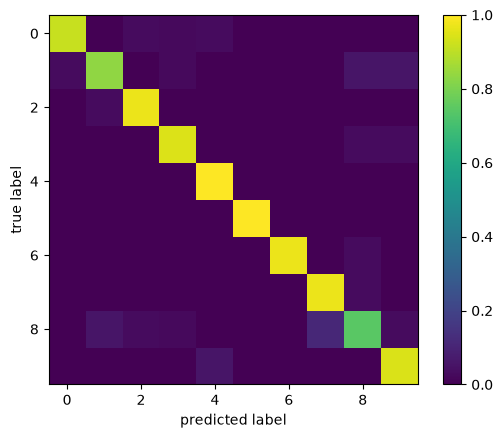

In [55]:
_,count = np.unique(np.argmax(y_test,axis=1),return_counts=True)
print (count)
CM = CM/count
CM = np.round(1000*CM)/1000

plt.figure('confusion matrix')
ax = plt.imshow(CM); plt.colorbar()
plt.ylabel('true label')
plt.xlabel('predicted label')

Evaluate the model on the test dataset. What is the accuracy on the test dataset? Use the model's class function **evaluate()**.


In [56]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)          


print ("The loss and accuracy on the test dataset : %f, %f"%(test_loss, test_accuracy))

The loss and accuracy on the test dataset : 0.248067, 0.930556


## **Conclusions:**
Conclude your report by answering the following questions:

1. Did your training converge? 
2. Was the training successful? 
3. Try to improve the model. Try adding the number of filters in the filter layer. Does the accuracy improve?
4. Could you obtain better results than with the perceptron?

In [57]:
# Accuracy du modèle initial
initial_val_accuracy = model.history.history["val_accuracy"][-1]

print("1. Yes, the validation loss decreased and the validation accuracy stabilized.")

print(f"2.Yes, the validation accuracy was {initial_val_accuracy:.2%}.")



1. Yes, the validation loss decreased and the validation accuracy stabilized.
2.Yes, the validation accuracy was 94.79%.


In [58]:
# 2. Code's amelioration with more filters
model_improved = Sequential([
    Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(8, 8, 1)
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(10, activation="softmax")
])

model_improved.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_improved = model_improved.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_data=(X_val, y_val),
    verbose=1
)

improved_val_accuracy = history_improved.history["val_accuracy"][-1]

print("\n3. Does adding more filters improve the accuracy?")
print(f"Original validation accuracy : {initial_val_accuracy:.2%}")
print(f"Improved validation accuracy : {improved_val_accuracy:.2%}")

if improved_val_accuracy > initial_val_accuracy:
    print("Yes, the accuracy improved.")
elif improved_val_accuracy < initial_val_accuracy:
    print("No, the accuracy decreased.")
else:
    print("The accuracy remained the same.")

print("\n4. Did the CNN obtain better results than the perceptron?")

print("Perceptron validation accuracy : 92.5%")

print(f"CNN validation accuracy: {improved_val_accuracy:.2%}")
print("CNN have better accuracy than the perceptron")

Epoch 1/20


/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1497 - loss: 4.0065 - val_accuracy: 0.2083 - val_loss: 2.4179
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4003 - loss: 1.8205 - val_accuracy: 0.5104 - val_loss: 1.4591
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6736 - loss: 1.1137 - val_accuracy: 0.7292 - val_loss: 0.9393
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8068 - loss: 0.7326 - val_accuracy: 0.8299 - val_loss: 0.6510
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8738 - loss: 0.5236 - val_accuracy: 0.8681 - val_loss: 0.5057
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8964 - loss: 0.4052 - val_accuracy: 0.9028 - val_loss: 0.3952
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9191 - loss: 0.3308 - val_accuracy: 0.9167 - val_loss: 0.3397
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9330 - loss: 0.2792 - val_accuracy: 0.9271 - val_loss: 0.2972
Epo

In [59]:
# from google.colab import drive
# base_working_dir = '/content/drive/My Drive/Colab Notebooks/MBE DL course'
# drive.mount('/content/drive')

# !sudo apt-get install texlive-xetex texlive-fonts-recommended texlive-generic-recommended

# !jupyter nbconvert --to pdf  "drive/My Drive/Colab Notebooks/MBE DL course/exercise_3_assignment.ipynb" #>/dev/null 2>/dev/null